In [1]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

df = load_wine()
X = df.data
y = df.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

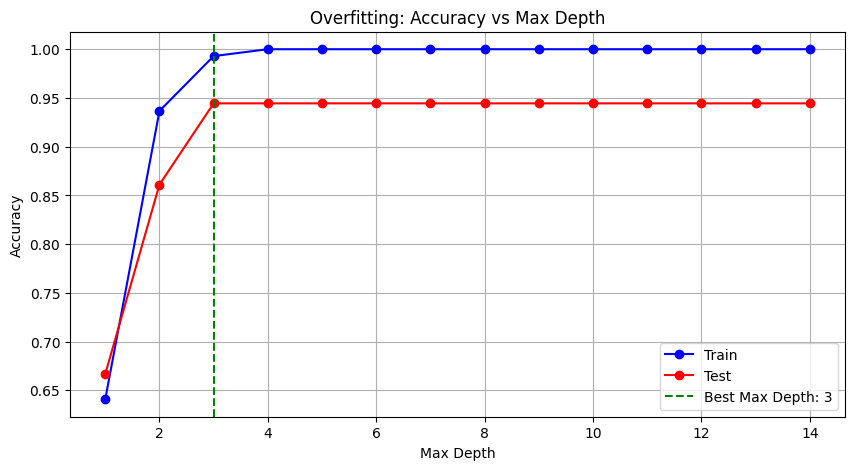

In [ ]:
# Lets see how different max_depths affect the model with graph

depths = list(range(1, 15))
train_scores = []
test_scores = []

for depth in depths:
  model = DecisionTreeClassifier(max_depth=depth, random_state=42)
  model.fit(X_train, y_train)
  train_scores.append(model.score(X_train, y_train))
  test_scores.append(model.score(X_test, y_test))


plt.figure(figsize=(10, 5))
plt.plot(depths, train_scores, "b-o", label='Train')
plt.plot(depths, test_scores, "r-o", label='Test')
best_max_depth = depths[np.argmax(test_scores)]
plt.axvline(x=best_max_depth, color='green', linestyle='--', label=f'Best Max Depth: {best_max_depth}')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Overfitting: Accuracy vs Max Depth')
plt.legend()
plt.grid(True)
plt.show()

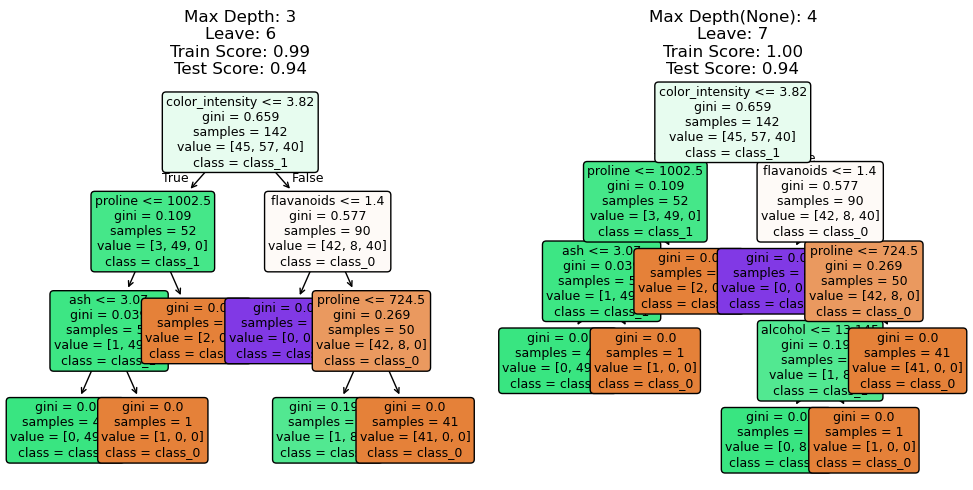

In [2]:
# lets compare simple tree and complex tree

# simple tree
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

simple = DecisionTreeClassifier(max_depth=3, random_state=42)
simple.fit(X_train, y_train)
plot_tree(simple, feature_names=df.feature_names, class_names = df.target_names,
          filled=True, rounded=True, ax=axes[0], fontsize=9)

axes[0].set_title(
    f"Max Depth: {simple.get_depth()}\n"
    f"Leave: {simple.get_n_leaves()}\n"
    f"Train Score: {simple.score(X_train, y_train):.2f}\n"
    f"Test Score: {simple.score(X_test, y_test):.2f}"
)


# complex tree no depths limited
complexx = DecisionTreeClassifier(max_depth=None, random_state=42)
complexx.fit(X_train, y_train)
plot_tree(complexx, feature_names=df.feature_names, class_names = df.target_names,
          filled=True, rounded=True, ax=axes[1], fontsize=9)

axes[1].set_title(
    f"Max Depth(None): {complexx.get_depth()}\n"
    f"Leave: {complexx.get_n_leaves()}\n"
    f"Train Score: {complexx.score(X_train, y_train):.2f}\n"
    f"Test Score: {complexx.score(X_test, y_test):.2f}")


plt.tight_layout()
plt.show()

In [3]:
# Random forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_wine

data = load_wine()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

dt = DecisionTreeClassifier(max_depth = 3, random_state=42)
rf = RandomForestClassifier(n_estimators = 100, random_state=42)

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

print(f"Decision Tree Accuracy: {dt.score(X_test, y_test):.4f}")
print(f"Random Forest Accuracy: {rf.score(X_test, y_test):.4f}")


Decision Tree Accuracy: 0.9444
Random Forest Accuracy: 1.0000


In [4]:
dt_scores = []
rf_scores = []


for i in range(1, 20):
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
  dt = DecisionTreeClassifier(random_state=42)
  rf = RandomForestClassifier(random_state=42)

  dt.fit(X_train, y_train)
  rf.fit(X_train, y_train)

  dt_scores.append(dt.score(X_test, y_test))
  rf_scores.append(rf.score(X_test, y_test))

print("---Decision Tree---")
print("Mean accuracy", np.mean(dt_scores))
print("Min accuracy", np.min(dt_scores))
print("Max accuracy", np.max(dt_scores))
print("Standard deviation", np.std(dt_scores))


print("\n---Random Forest---")
print("Mean accuracy", np.mean(rf_scores))
print("Min accuracy", np.min(rf_scores))
print("Max accuracy", np.max(rf_scores))
print("Standard deviation", np.std(rf_scores))


---Decision Tree---
Mean accuracy 0.9629629629629628
Min accuracy 0.9629629629629629
Max accuracy 0.9629629629629629
Standard deviation 1.1102230246251565e-16

---Random Forest---
Mean accuracy 1.0
Min accuracy 1.0
Max accuracy 1.0
Standard deviation 0.0
